<a href="https://colab.research.google.com/github/alightnessaron-afk/COU07506-labs./blob/main/COU07506_Week02_240242425544.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

COU 07506 – Digital Signal Processing

Week 2: Lab 1A – Sampling, Aliasing and Quantization

Name: Lightness Aron Japheti

Registration Number: 240242425544


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

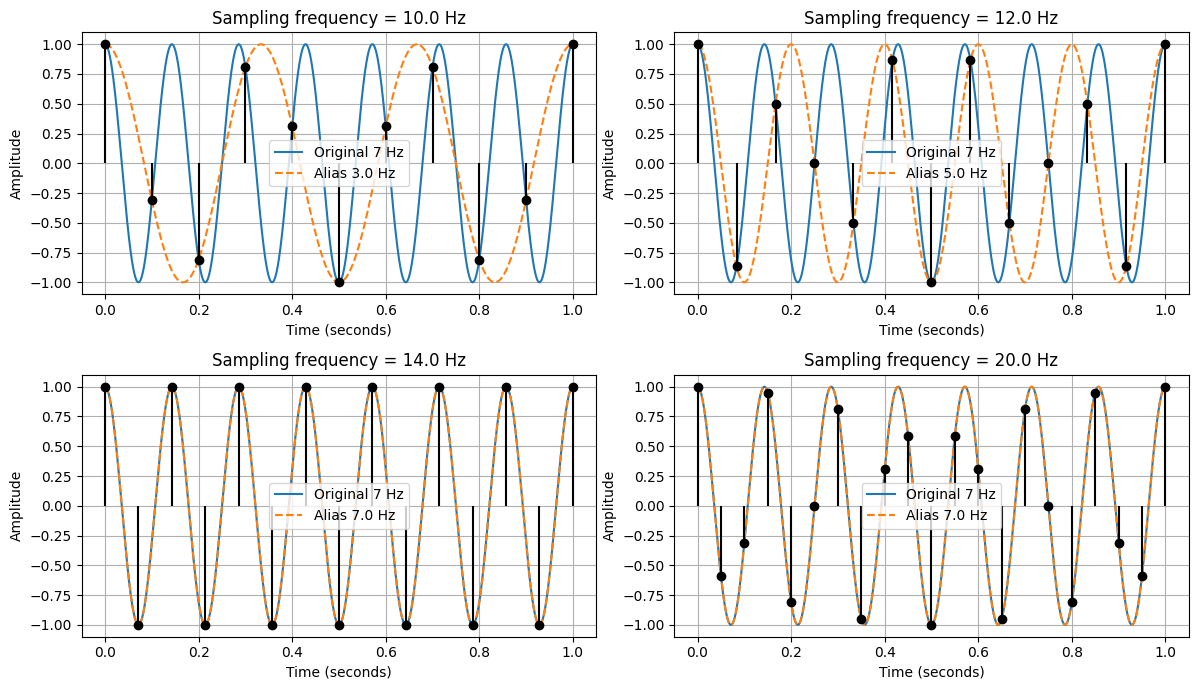

In [2]:
f0 = 7.0

sampling_rates = [10.0, 12.0, 14.0, 20.0]

t = np.linspace(0, 1, 2000)

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, fs in zip(axes.flatten(), sampling_rates):

    n = np.arange(0, int(fs) + 1)
    tn = n / fs

    f_alias = abs(f0 - fs * round(f0 / fs))

    x = np.cos(2 * np.pi * f0 * t)
    alias = np.cos(2 * np.pi * f_alias * t)

    ax.plot(t, x, label="Original 7 Hz")
    ax.plot(t, alias, "--", label=f"Alias {f_alias} Hz")

    ax.stem(
        tn,
        np.cos(2 * np.pi * f0 * tn),
        linefmt="k-",
        markerfmt="ko",
        basefmt=" "
    )

    ax.set_title(f"Sampling frequency = {fs} Hz")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

In [4]:
import librosa
import soundfile as sf

audio, fs = librosa.load("/content/light audio.aac", sr=None)

sf.write("my_voice.wav", audio, fs)

/tmp/ipykernel_555/496351905.py:4: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, fs = librosa.load("/content/light audio.aac", sr=None)


In [5]:
import os

fname = "my_voice.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)

    x = x.astype(float)

    if x.ndim > 1:
        x = x.mean(axis=1)

    peak = np.max(np.abs(x))

    if peak > 0:
        x = x / peak

else:
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5 * signal.chirp(t, 200, 3, 15000)

print("Sampling rate:", fs, "Hz")
print("Number of samples:", len(x))

Sampling rate: 44100 Hz
Number of samples: 195584


In [6]:
from IPython.display import Audio, display

for k in [2, 4, 8]:

    naive = x[::k]

    proper = signal.decimate(x, k, ftype="fir")

    new_fs = fs // k

    print("Downsampling factor:", k)
    print("New sampling rate:", new_fs, "Hz")

    print("Naive audio:")
    display(Audio(naive, rate=new_fs))

    print("Filtered audio:")
    display(Audio(proper, rate=new_fs))

Downsampling factor: 2
New sampling rate: 22050 Hz
Naive audio:


Filtered audio:


Downsampling factor: 4
New sampling rate: 11025 Hz
Naive audio:


Filtered audio:


Downsampling factor: 8
New sampling rate: 5512 Hz
Naive audio:


Filtered audio:


In [7]:
def quantize(x, bits, full_scale=1.0):

    delta = 2 * full_scale / 2**bits

    q = np.round(x / delta) * delta

    return np.clip(q, -full_scale, full_scale - delta)

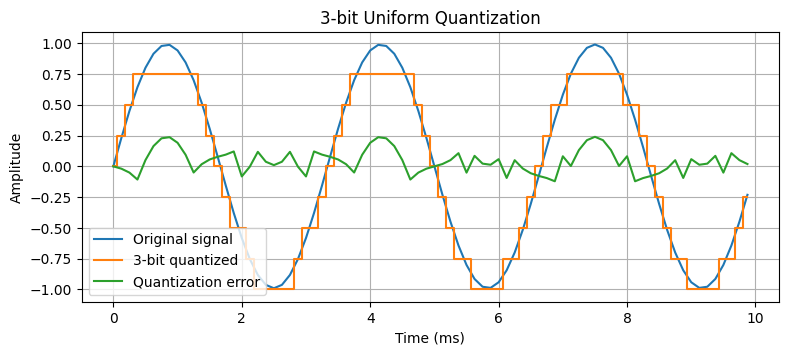

In [8]:
fs = 8000

t = np.arange(0, 0.01, 1/fs)

x = 0.99 * np.sin(2 * np.pi * 300 * t)

xq = quantize(x, 3)

plt.plot(t * 1e3, x, label="Original signal")

plt.step(t * 1e3, xq, where="mid", label="3-bit quantized")

plt.plot(t * 1e3, x - xq, label="Quantization error")

plt.title("3-bit Uniform Quantization")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

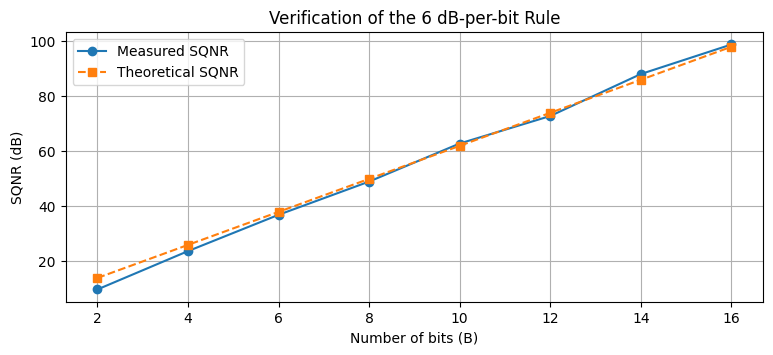

In [9]:
bits = np.arange(2, 17, 2)

meas = [
    10 * np.log10(
        np.sum(x**2) /
        np.sum((x - quantize(x, B))**2)
    )
    for B in bits
]

theoretical = 6.02 * bits + 1.76

plt.plot(bits, meas, "o-", label="Measured SQNR")
plt.plot(bits, theoretical, "s--", label="Theoretical SQNR")

plt.title("Verification of the 6 dB-per-bit Rule")
plt.xlabel("Number of bits (B)")
plt.ylabel("SQNR (dB)")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
fs, voice = wavfile.read("my_voice.wav")

voice = voice.astype(float)

if voice.ndim > 1:
    voice = voice.mean(axis=1)

peak = np.max(np.abs(voice))

if peak > 0:
    voice = voice / peak

print("Sampling rate:", fs, "Hz")
print("Number of samples:", len(voice))

Sampling rate: 44100 Hz
Number of samples: 195584


In [11]:
from IPython.display import Audio, display

for B in [4, 8, 12]:

    voice_q = quantize(voice, B)

    error = voice - voice_q

    sqnr = 10 * np.log10(
        np.sum(voice**2) / np.sum(error**2)
    )

    print("Bits:", B)
    print("SQNR:", round(sqnr, 2), "dB")

    display(Audio(voice_q, rate=fs))

Bits: 4
SQNR: 3.52 dB


Bits: 8
SQNR: 23.57 dB


Bits: 12
SQNR: 46.19 dB


Explain, with a frequency-axis sketch, why the 7 Hz tone appears at 3 Hz when f_s=10 Hz.
Answer:

When a 7 Hz signal is sampled at 10 Hz, its frequency is above the Nyquist frequency, which is 5 Hz. Therefore, aliasing occurs. The apparent frequency is:

f_(alias)=|f_s-f|


=|10-7|=3Hz


2. In Task 2.2, why can the aliasing heard in the naïve version not be removed afterwards?
Answer:

Aliasing cannot be removed after sampling because high-frequency components have already been confused with lower-frequency components. The original frequency information is lost during sampling. An anti-aliasing filter must be applied before downsampling to prevent this problem.

3. By how much does the SQNR change when one bit is added? Does your measurement agree?
Answer:

The SQNR increases by approximately 6.02 dB for every additional bit.

SQNR=6.02B+1.76 dB


The measured results should approximately agree with the theoretical values. Small differences may occur due to quantization and the characteristics of the input signal.

4. A temperature sensor changes by at most 0.1 °C per second and the required resolution is 0.01 °C over a range of 0–100 °C. Suggest a sampling rate and number of bits, and justify them.
Answer:

I suggest a sampling rate of 10 samples per second (10 Hz) and a 14-bit quantizer.

Justification:
- The sensor changes by at most 0.1 °C per second. At 10 samples per second, the maximum change between consecutive samples is approximately 0.01 °C.
- The required temperature resolution is 0.01 °C over a range of 100 °C.
Number of levels required:

L=(100/0.01)=10,000

Number of bits:

B=log_2(10,000)=14


A 14-bit quantizer provides 16,384 levels, which is sufficient to meet the required resolution.

Note: The 10 Hz sampling rate is a practical design suggestion based on the stated rate of temperature change, rather than a Nyquist rate derived from a specified signal frequency.